In [1]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

#This is the function for plotting the feature maps
def plot_feature_maps(feature_maps):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    for ax, feature in zip(axes.flat, feature_maps):
        # Treat the first 8 channels as 8 single-channel images.
        channel_maps = feature.detach()[0, :8].unsqueeze(1)  # [8, 1, H, W]

        grid = make_grid(
            channel_maps,
            nrow=4,
            normalize=True,
            scale_each=True,
            padding=2,
        )

        ax.imshow(grid.permute(1, 2, 0).cpu().numpy())  # CHW -> HWC
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [2]:
import matplotlib.pyplot as plt
import torch

def plot_single_feature_map(feature_maps, channel_idx=0, filename=None):
    fig, ax = plt.subplots(figsize=(6, 6))

    single_map = feature_maps[0].detach()[0, channel_idx].cpu().numpy()
    ax.imshow(single_map, cmap="viridis")
    ax.axis("off")
    plt.tight_layout()

    if filename:
        fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

# --- How to use it ---
# Assuming 'baseline_L4_maps' is your tensor of baseline layer 4 activations
# plot_single_feature_map(baseline_L4_maps, channel_idx=12)

# Mechanistic Interpretability: Tensor Format

When extracting feature maps from a neural network, it is critical to understand how the framework organizes the dimensions of the data. The two standard formats are **NCHW** and **NHWC**.

### 1. PyTorch: NCHW (Channels First)
PyTorch uses the `[Batch, Channels, Height, Width]` format.

*   **Layout:** The color channels (e.g., RGB or the 32/64 filters of a Conv layer) are placed before the spatial dimensions.
*   **Why PyTorch uses it:** Historically, PyTorch was built around NVIDIA's cuDNN library, which was highly optimized for the NCHW memory layout. This makes it highly efficient for deep learning research and tensor operations on NVIDIA GPUs.
*   **How to slice:** To extract a single filter (channel) from a tensor in PyTorch, you slice the second dimension: `tensor[batch, channel, :, :]`.

### 2. Keras/TensorFlow: NHWC (Channels Last)
Keras uses the `[Batch, Height, Width, Channels]` format.

*   **Layout:** The color channels are placed at the very end, after the spatial dimensions.
*   **Why Keras uses it:** This layout is optimized for "memory coalescing" on modern GPUs and TPUs. It allows the hardware to read the RGB values of a single pixel in one fast memory operation.
*   **How to slice:** To extract a single filter in Keras, you slice the last dimension: `tensor[batch, :, :, channel]`.

---

### The Matplotlib Gotcha
When visualizing these tensors, `matplotlib` expects an image to be in **HWC** (Height, Width, Channels) format.

Because PyTorch outputs **NCHW**, you often have to `permute` or transpose the tensor before plotting it. Additionally, you must call `.detach().cpu().numpy()` on the PyTorch tensor first, as `matplotlib` cannot plot tensors that are attached to the computation graph (gradients).

In [3]:
import torch
from models.naimishnet import NaimishNet
from src.extract_features import extract_features

# Load the model (untrained is fine for the dummy test)
model = NaimishNet()

# Create the dummy image tensor
dummy_input = torch.randn(1, 1, 96, 96)

# Call the function
features = extract_features(model, dummy_input)

# Print the shapes
for f in features:
    print(f.shape)

torch.Size([1, 32, 93, 93])
torch.Size([1, 64, 44, 44])
torch.Size([1, 128, 21, 21])
torch.Size([1, 256, 10, 10])


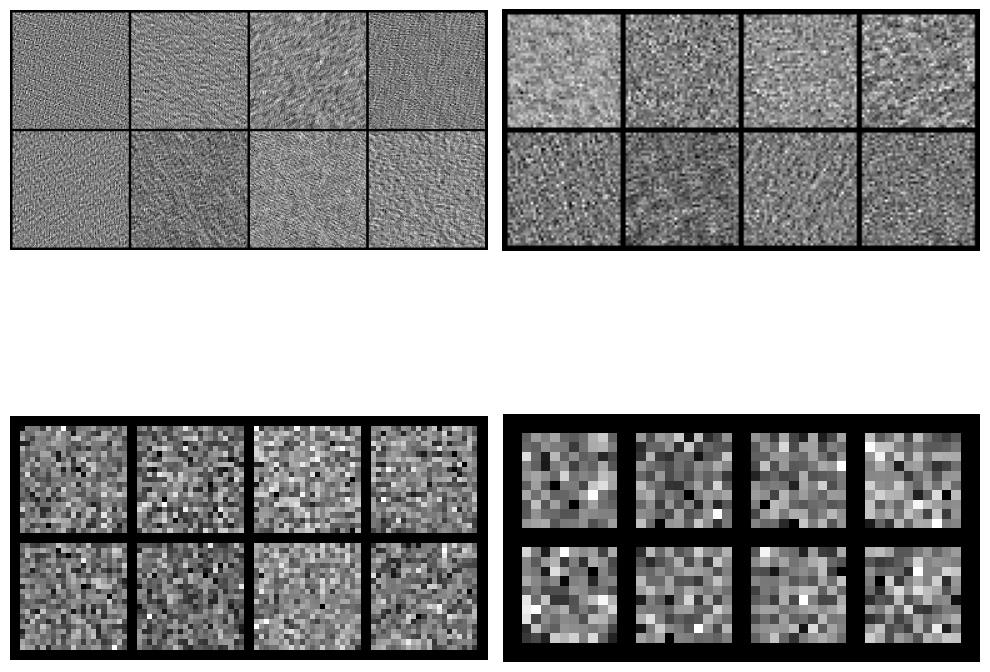

In [4]:
# Call the function and pass the features list into it
plot_feature_maps(features)

Those are the untrained feature maps extracted from the first convolutional layer of the model. Each feature map corresponds to a different filter applied to the input image, capturing various aspects of the image such as edges, textures, and patterns.
you can see that the feature maps are not very informative at this stage, as the model has not yet learned to recognize meaningful features from the data. As the model is trained, these feature maps will become more refined and will start to capture more complex patterns in the input images. The weight is randomly initialized, so the feature maps are essentially random noise at this point. However, as the model is trained, the filters will learn to detect specific features in the input images, and the feature maps will become more informative and useful for downstream tasks such as classification or object detection.

Now we load our trained model and extract the feature maps again to see how they have changed after training.

In [5]:
import numpy as np
import torch
from models.naimishnet import NaimishNet
from src.data_pipeline import FacialKeypointsDataset
from src.extract_features import extract_features

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_dataset = FacialKeypointsDataset(
    csv_file="data/test_frames_keypoints.csv",
    root_dir="data/test",
)
image = test_dataset[0]["image"].unsqueeze(0).to(device)


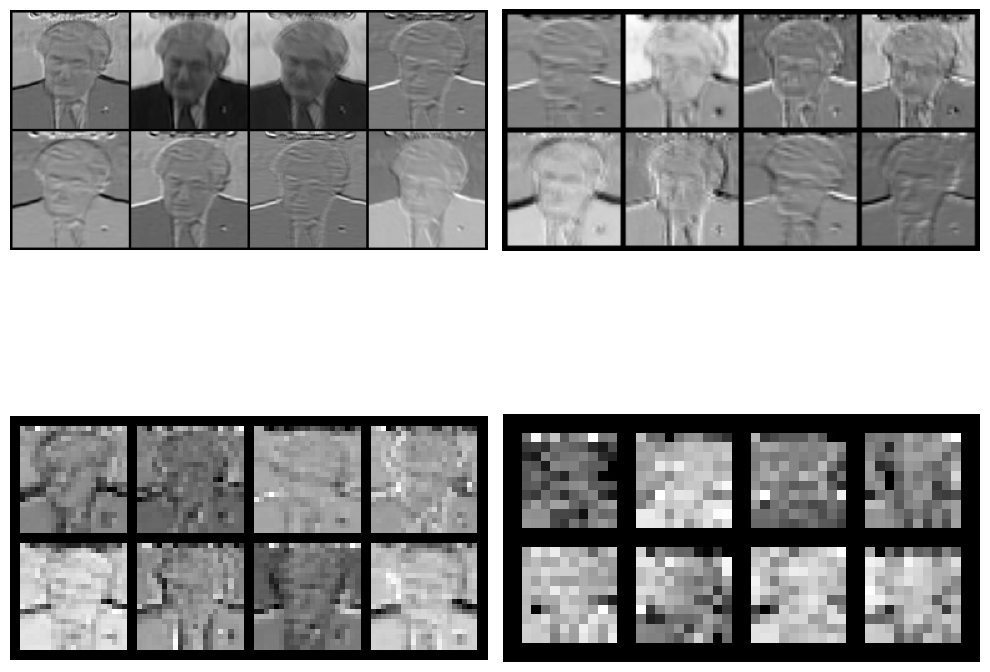

In [6]:
baseline = NaimishNet(use_bam_and_coord=False).to(device).eval()

with torch.no_grad():
    baseline(image)

baseline.load_state_dict(
    torch.load("output/naimishnet_aligned.pth", map_location=device, weights_only=True)
)
baseline_features = extract_features(baseline, image)

np.save("rust_data_pipeline/baseline_layer1.npy",
        baseline_features[0][0].detach().cpu().numpy())
np.save("rust_data_pipeline/baseline_layer4.npy",
        baseline_features[3][0].detach().cpu().numpy())

plot_feature_maps(baseline_features[:4])

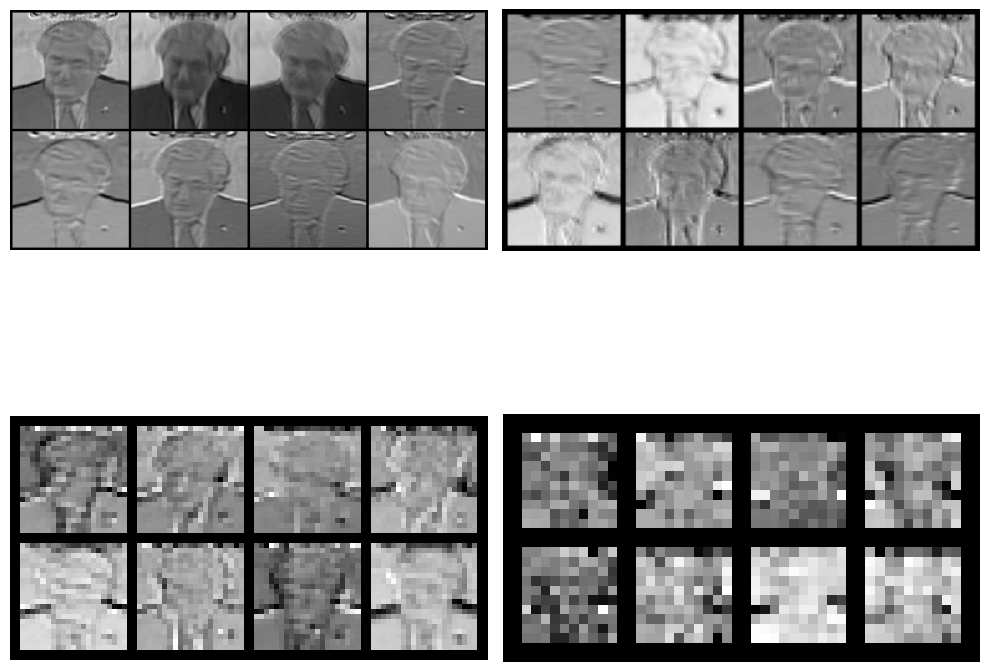

In [8]:
advanced = NaimishNet(use_bam_and_coord=True).to(device).eval()

with torch.no_grad():
    advanced(image)  # Initialize lazy layer

advanced.load_state_dict(
    torch.load("output/naimishnet_bam_coord_aligned.pth", map_location=device, weights_only=True)
)
advanced_features = extract_features(advanced, image)

np.save("rust_data_pipeline/advanced_layer1.npy", advanced_features[0][0].detach().cpu().numpy())
np.save("rust_data_pipeline/advanced_layer4.npy", advanced_features[3][0].detach().cpu().numpy())

plot_feature_maps(advanced_features[:4])

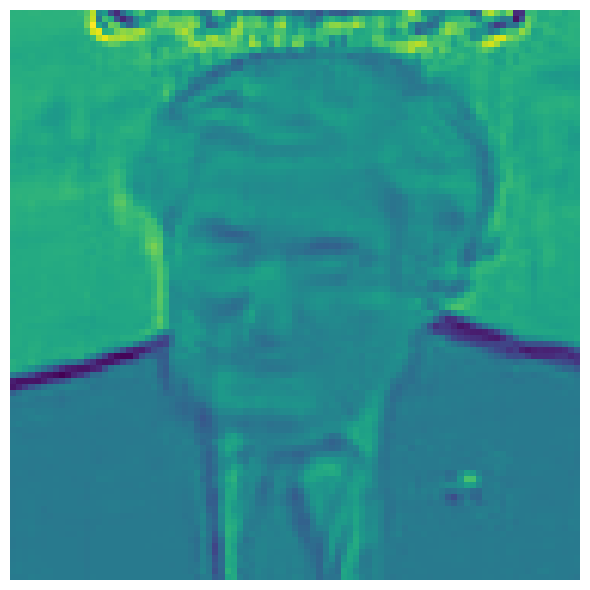

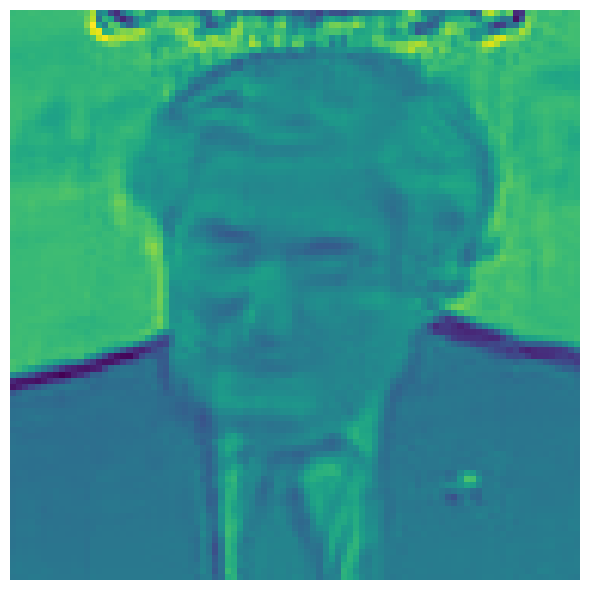

In [10]:
plot_single_feature_map(baseline_features, filename="baseline.png")
plot_single_feature_map(advanced_features, filename="advanced.png")